# Create Master Flat, Perform Dark Current Subtraction

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import glob
from astropy.io import fits
from natsort import natsorted


Text(0, 0.5, 'y [pix]')

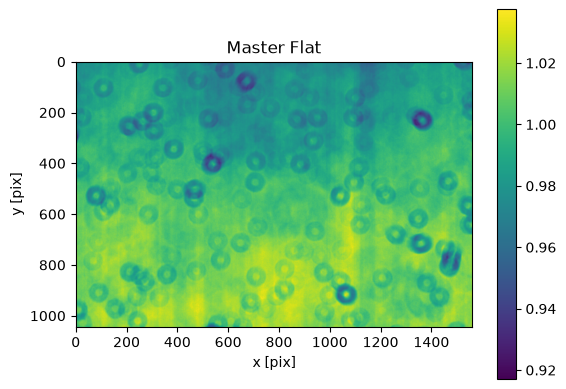

In [2]:
dark_7_5_data = []
for filename in glob.glob("../data/pegasi/raw_data/Dark-7-5*"):
    data = fits.getdata(filename).astype(np.float64)
    dark_7_5_data.append(data)
master_dark_7_5 = np.median(dark_7_5_data, axis=0)

flat_data = []
for filename in glob.glob("../data/pegasi/raw_data/Flat-V-7-5*"):
    data = fits.getdata(filename).astype(np.float64)
    data -= master_dark_7_5
    flat_data.append(data)
combined_flat = np.median(flat_data, axis=0)
master_flat = combined_flat / np.median(combined_flat, axis=0)

plt.imshow(master_flat)
plt.colorbar()
plt.title("Master Flat")
plt.xlabel("x [pix]")
plt.ylabel("y [pix]")

# Apply preprocessing and save

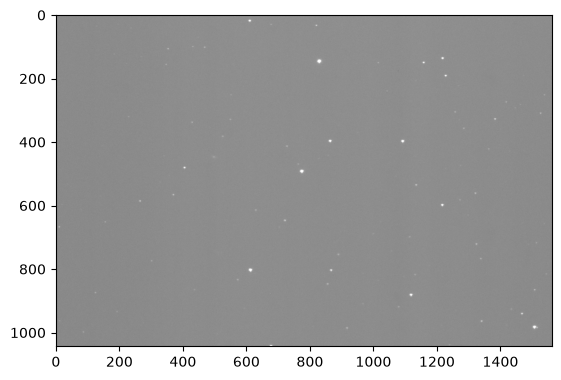

In [3]:
dark_60 = []
for filename in glob.glob("../data/pegasi/raw_data/Dark-60*"):
    data = fits.getdata(filename).astype(np.float64)
    dark_60.append(data)
master_dark_60 = np.median(dark_60, axis=0)

preprocessed_data = []
for filename in natsorted(glob.glob("../data/pegasi/raw_data/Peg-V*")):
    data = fits.getdata(filename).astype(np.float64)
    data -= master_dark_60
    data /= master_flat
    preprocessed_data.append(data)

for i, data in enumerate(preprocessed_data):
    fits.writeto(filename = f"../data/pegasi/preprocessed_data/preprocessed_peg{i}.fits",
                 data = data)

plt.imshow(np.log10(preprocessed_data[0]), vmax=3, cmap="grey")

# Run astrometry.net

To run astrometry.net, the following bash script is used to save the WCS-solved data in the `wcs_calibrated_data/` directory:

```bash
#! /bin/bash -u

for file in $(ls -1 data/pegasi/preprocessed_data/*.fits)
do
   solve-field ${file} -m data/pegasi/wcs_calibrated_data/
done
```

Following this, we run Source Extractor to obtain fluxes in circular apertures of diameter 25 pixels:
```bash
#! /bin/bash -u

for file in $(ls -1 data/pegasi/wcs_calibrated_data/*.new)
do
   sex ${file} -c default.se -CATALOG_NAME ${file}.cat
done
```

# Get the raw data of DY Pegasi and reference stars

The star at coordinates (RA, DEC) = (23:09:05, 17:08:19) is chosen to be the reference star from which the apparent magntiudes of the variable star will be calculated. According to SIMBAD, it has a V-band apparent magnitude of 9.91.

In [2]:
from natsort import natsorted
import glob
import numpy as np

def extract_data(filename, ra_bounds, dec_bounds, epsilon=0.0001):
    data = np.loadtxt(filename)

    ra = data[:, 0]
    dec = data[:, 1]

    ra_lower, ra_upper = ra_bounds
    dec_lower, dec_upper = dec_bounds

    index = (
        (ra >= ra_lower - epsilon) & (ra <= ra_upper + epsilon) &
        (dec >= dec_lower - epsilon) & (dec <= dec_upper + epsilon)
    )

    flux = data[index, 2]
    flux_error = data[index, 3]

    return flux, flux_error


files = natsorted(glob.glob("../data/pegasi/wcs_calibrated_data/*.cat"))

ra_peg_bounds = (347.212, 347.214)
dec_peg_bounds = (17.214, 17.216)

ra_ref_bounds = [
    (347.26, 347.28),

]

dec_ref_bounds = [
    (17.137, 17.139)
]


peg_fluxes = []
peg_sigmas = []
ref_fluxes = []
ref_sigmas = []
for filename in files:
    flux, err = extract_data(filename, ra_peg_bounds, dec_peg_bounds)
    peg_fluxes.append(flux)
    peg_sigmas.append(err)

for i, (ra_bounds, dec_bounds) in enumerate(zip(ra_ref_bounds, dec_ref_bounds)):
    key = f"ref{i+1}"

    for filename in files:
        flux, err = extract_data(filename, ra_bounds, dec_bounds)
        ref_fluxes.append(flux)
        ref_sigmas.append(err)

from astropy.time import Time
header_files = natsorted(glob.glob("../data/pegasi/raw_data/Peg*"))
exp_dates = []
for filename in header_files:
    header = fits.getheader(filename)
    time = Time(header["DATE-OBS"], format='fits', scale='utc')
    exp_dates.append(time.jd)

In [11]:
# sometimes the reference star is out of the frame, so mask those with the average value
ref_flux = np.array([f[0] if np.size(f) > 0 else np.nan for f in ref_fluxes], dtype=float)
mask = np.isfinite(ref_flux)
new_ref = np.where(mask, ref_flux, np.nanmean(ref_flux))

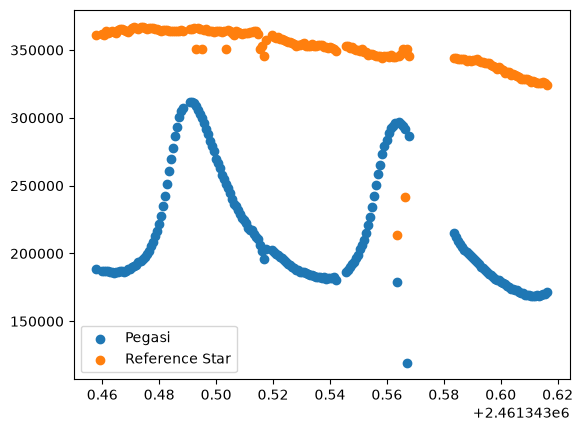

In [12]:
plt.scatter(exp_dates[1:], peg_fluxes, label="Pegasi")
plt.scatter(exp_dates[1:], new_ref, label="Reference Star")
plt.legend()

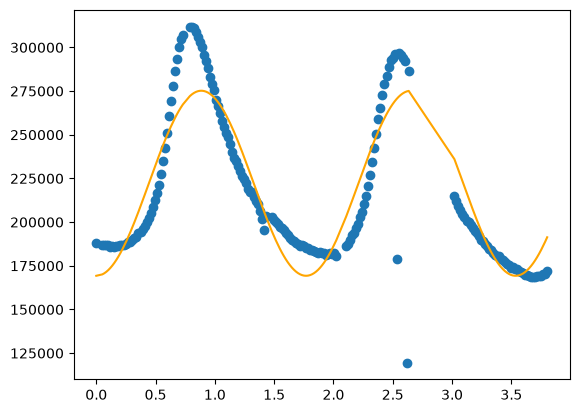

In [13]:
from scipy.optimize import curve_fit

def cos_fit(x, A, omega, phi, C):
    return A*np.cos(omega*x + phi) + C

x = np.asarray(exp_dates[1:], dtype=float).ravel()
x_hours = (x - x[0]) * 24.0
y = np.asarray(peg_fluxes).ravel()

p0 = [(y.max()-y.min())/2, 2*np.pi/1.75, 0, y.mean()]
popt, pcov = curve_fit(f=cos_fit, xdata=x_hours, ydata=y, p0=p0)

plt.scatter(x_hours, y)
plt.plot(x_hours, cos_fit(x_hours, popt[0], popt[1], popt[2], popt[3]), color="orange")

# Error Propagation

For the function
$$
\rm T(\omega) = \frac{2 \pi}{\omega},
$$
the first-order correction for error is:
$$
\rm \sigma_{T} = T \sqrt{(\frac{\sigma_\omega}{\omega})^2},
$$
where $\sigma_{\omega}$ comes from the `curve_fit` covariance matrix diagonal.

In [14]:
w = popt[1]
T = 2*np.pi / w
sigma_w = np.sqrt(np.diag(pcov)[1])
sigma_T = T * np.sqrt((sigma_w / w)**2)

print(f"RESULT: T = {T:.3f} +- {sigma_T:.3f} hours")

RESULT: T = 1.767 +- 0.019 hours


This result matches quite nicely to the literature value of ~1.75 hours. We can now determine the absolute magnitude of DY Pegasi based upon the SX Phoenicis and Delta Scuti period-luminosity relation:
$$
\rm M = -3.725\log{P} - 1.933,
$$
with
$$
\rm \sigma_M = 3.725 \frac{\sigma_P}{P}
$$

In [15]:
T_days = T / 24
sigma_T_days = sigma_T / 24

M = -3.725*np.log10(T_days)  - 1.933
sigma_M = 3.725 * sigma_T_days / T_days

print(f"M = {M:.2f} +/- {sigma_M:.2f}")

M = 2.29 +/- 0.04


This closely matches the observed value of M = 2.34!

# Compute Apparent Magnitude

The apparent magnitude of DY Pegasi can be computed from information of another star of known apparent magnitude in the image. The star at coordinates (RA, DEC) = (23:09:05, 17:08:19) has a V-band apparent magnitude of 9.91 according to SIMBAD. The relation of magnitudes and fluxes between two objects follows as:
$$
\rm m_1 - m_2 = -2.5\log{\frac{F_1}{F_2}},
$$
where $\rm F_i$ are the fluxes of the respective stars from photometry.

In [27]:
m_ref = 9.91

m = -2.5*np.log10(np.asarray(peg_fluxes).ravel() / np.asarray(new_ref).ravel()) + m_ref
sigma_m = np.std(m)
m_mean = np.mean(m)
print(f"m = {m_mean:.2f} +/- {sigma_m:.2f}")

m = 10.46 +/- 0.20


# Compute the distance to DY Pegasi

The distance modulus follows as:
$$
\rm m - M = 5\log{d} - 5,
$$
so the distance, in parsec, to DY Pegasi is:
$$
\rm d = 10^{\frac{m - M}{5}+1},
$$
where
$$
\rm \sigma_d = \frac{\ln{10}}{5}d\sqrt{\sigma_m^2+\sigma_M^2}
$$

In [28]:
d = 10**((m_mean-M)/5 + 1)
sigma_d = np.log(10)/5 * d * np.sqrt(sigma_m**2 + sigma_M**2)

print(f"Distance = {d:.2f} +/- {sigma_d:.2f} parsec")

Distance = 431.60 +/- 39.61 parsec


Text(0.0, 10.9, 'Distance = 431.60 +/- 39.61 parsec')

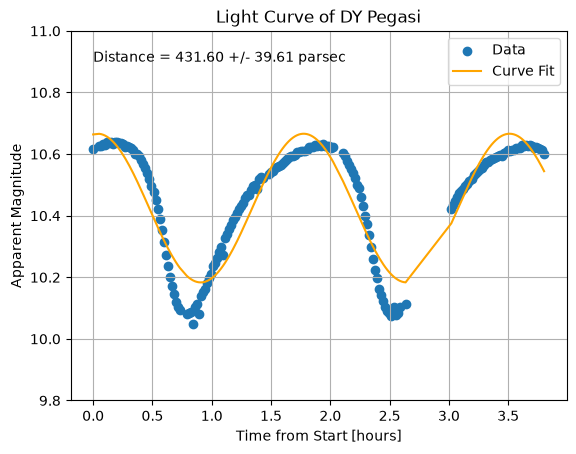

In [47]:
def cos_func(x, A, omega, phi, C):
    return A*np.cos(2*np.pi*omega*x + phi) + C

p0 = [(max(m) - min(m) / 2), 1.75, 0, max(m)]

popt, pcov = curve_fit(cos_func, x_hours, m)

plt.scatter(x_hours, m, label="Data")
plt.plot(x_hours, cos_func(x_hours, popt[0], popt[1], popt[2], popt[3]), color="orange", label="Curve Fit")
plt.xlabel("Time from Start [hours]")
plt.ylabel("Apparent Magnitude")
plt.title("Light Curve of DY Pegasi")
plt.ylim(bottom=9.8, top=11.)
plt.grid()
plt.legend()
plt.text(x=0., y =10.9, s="Distance = 431.60 +/- 39.61 parsec")